# 07 · ModernBERT-base, fully fine-tuned: the method `modernbert_base_full`

The method `modernbert_lora` ([notebook 06](06_modernbert_lora.ipynb)) trains LoRA updates on
ModernBERT-large. This one, `modernbert_base_full`, takes the other road:
[ModernBERT-base](https://huggingface.co/answerdotai/ModernBERT-base) (150M parameters, the same
tokenizer and 8,192-token context), with **every weight fine-tuned**, no LoRA. The protocol is
`modernbert_lora`'s, so the two compare on the same problems; the inputs are longer, 2,048
tokens, since the base model costs half as much per token.

Both are tagging methods of the framework
([ADR 0004](../docs/adr/0004-tagging-method-framework.md)): their code is the package
`codeforces_tags.methods.modernbert`, and their frozen files are in `assets/methods/<name>/`. This
notebook reads those files; it trains, tunes and loads no model.

**Protocol** ([ADR 0005](../docs/adr/0005-fine-tuned-model-protocol.md), as for
`modernbert_lora`):
1. **Tune on one fold.** An Optuna study trains on dev folds 1-4 and scores fold 0 after each
   epoch, for 30 trials, on fold 0's macro F1 at the last epoch, with per-tag thresholds
   cross-fitted across 5 sub-folds of fold 0. The search space is that of full fine-tuning:
   lower learning rates, and weight decay and classifier dropout instead of LoRA's rank and
   dropout.
2. **One model per fold, one shot.** The chosen configuration trains 5 fold models, each on 4 of
   the 5 dev folds. Their out-of-fold scores, predicted with thresholds cross-fitted across the
   folds, are the method's dev predictions; their macro F1 is compared, paired, with the TF-IDF
   baseline, `modernbert_lora` and the label prior.
3. **The bag is the method.** On the test set, the 5 fold models' probabilities are averaged,
   with per-tag thresholds chosen on every out-of-fold score. The bag is fixed before any test
   score is seen; each single fold model, the TF-IDF baseline, `modernbert_lora`'s bag and the
   label prior are scored beside it, as references.
4. **One model on the GPU.** Without LoRA the five fold models share no weights: each is a full
   copy of the encoder. The GPU holds one model, and the five sets of weights wait in pinned CPU
   memory, to be copied into it in turn (section 7 also shows the five models kept on the GPU).

**Contents**
1. Setup
2. The inputs: statement and solution in 2,048 tokens
3. The model and its training
4. The tuning study, on one fold
5. Five fold models with the chosen configuration
6. The test set, scored once: with and without bagging
7. Latency and memory
8. Takeaways and next steps

**Running it.** It needs no GPU and takes a minute or two. It reads the dataset and the frozen
files of `modernbert_base_full`, `modernbert_lora`, `tfidf` (the TF-IDF baseline) and
`label_prior` in `assets/methods/`. It needs the `finetuning` dependency group
(`uv sync --group finetuning`) and the method's pinned pretrained snapshot (the method's `fetch`
command) only for the tokenizer, which counts the tokens of section 2. The method was
frozen by the commands that CLAUDE.md lists (Commands): `fetch`, `export` (the study's results),
`adopt` (the fold models), `freeze`, `verify`, then `python -m codeforces_tags.tracking latency`
and `latency-cpu` (section 7). Sections 4 and 5 say where the study and the fold models come
from.

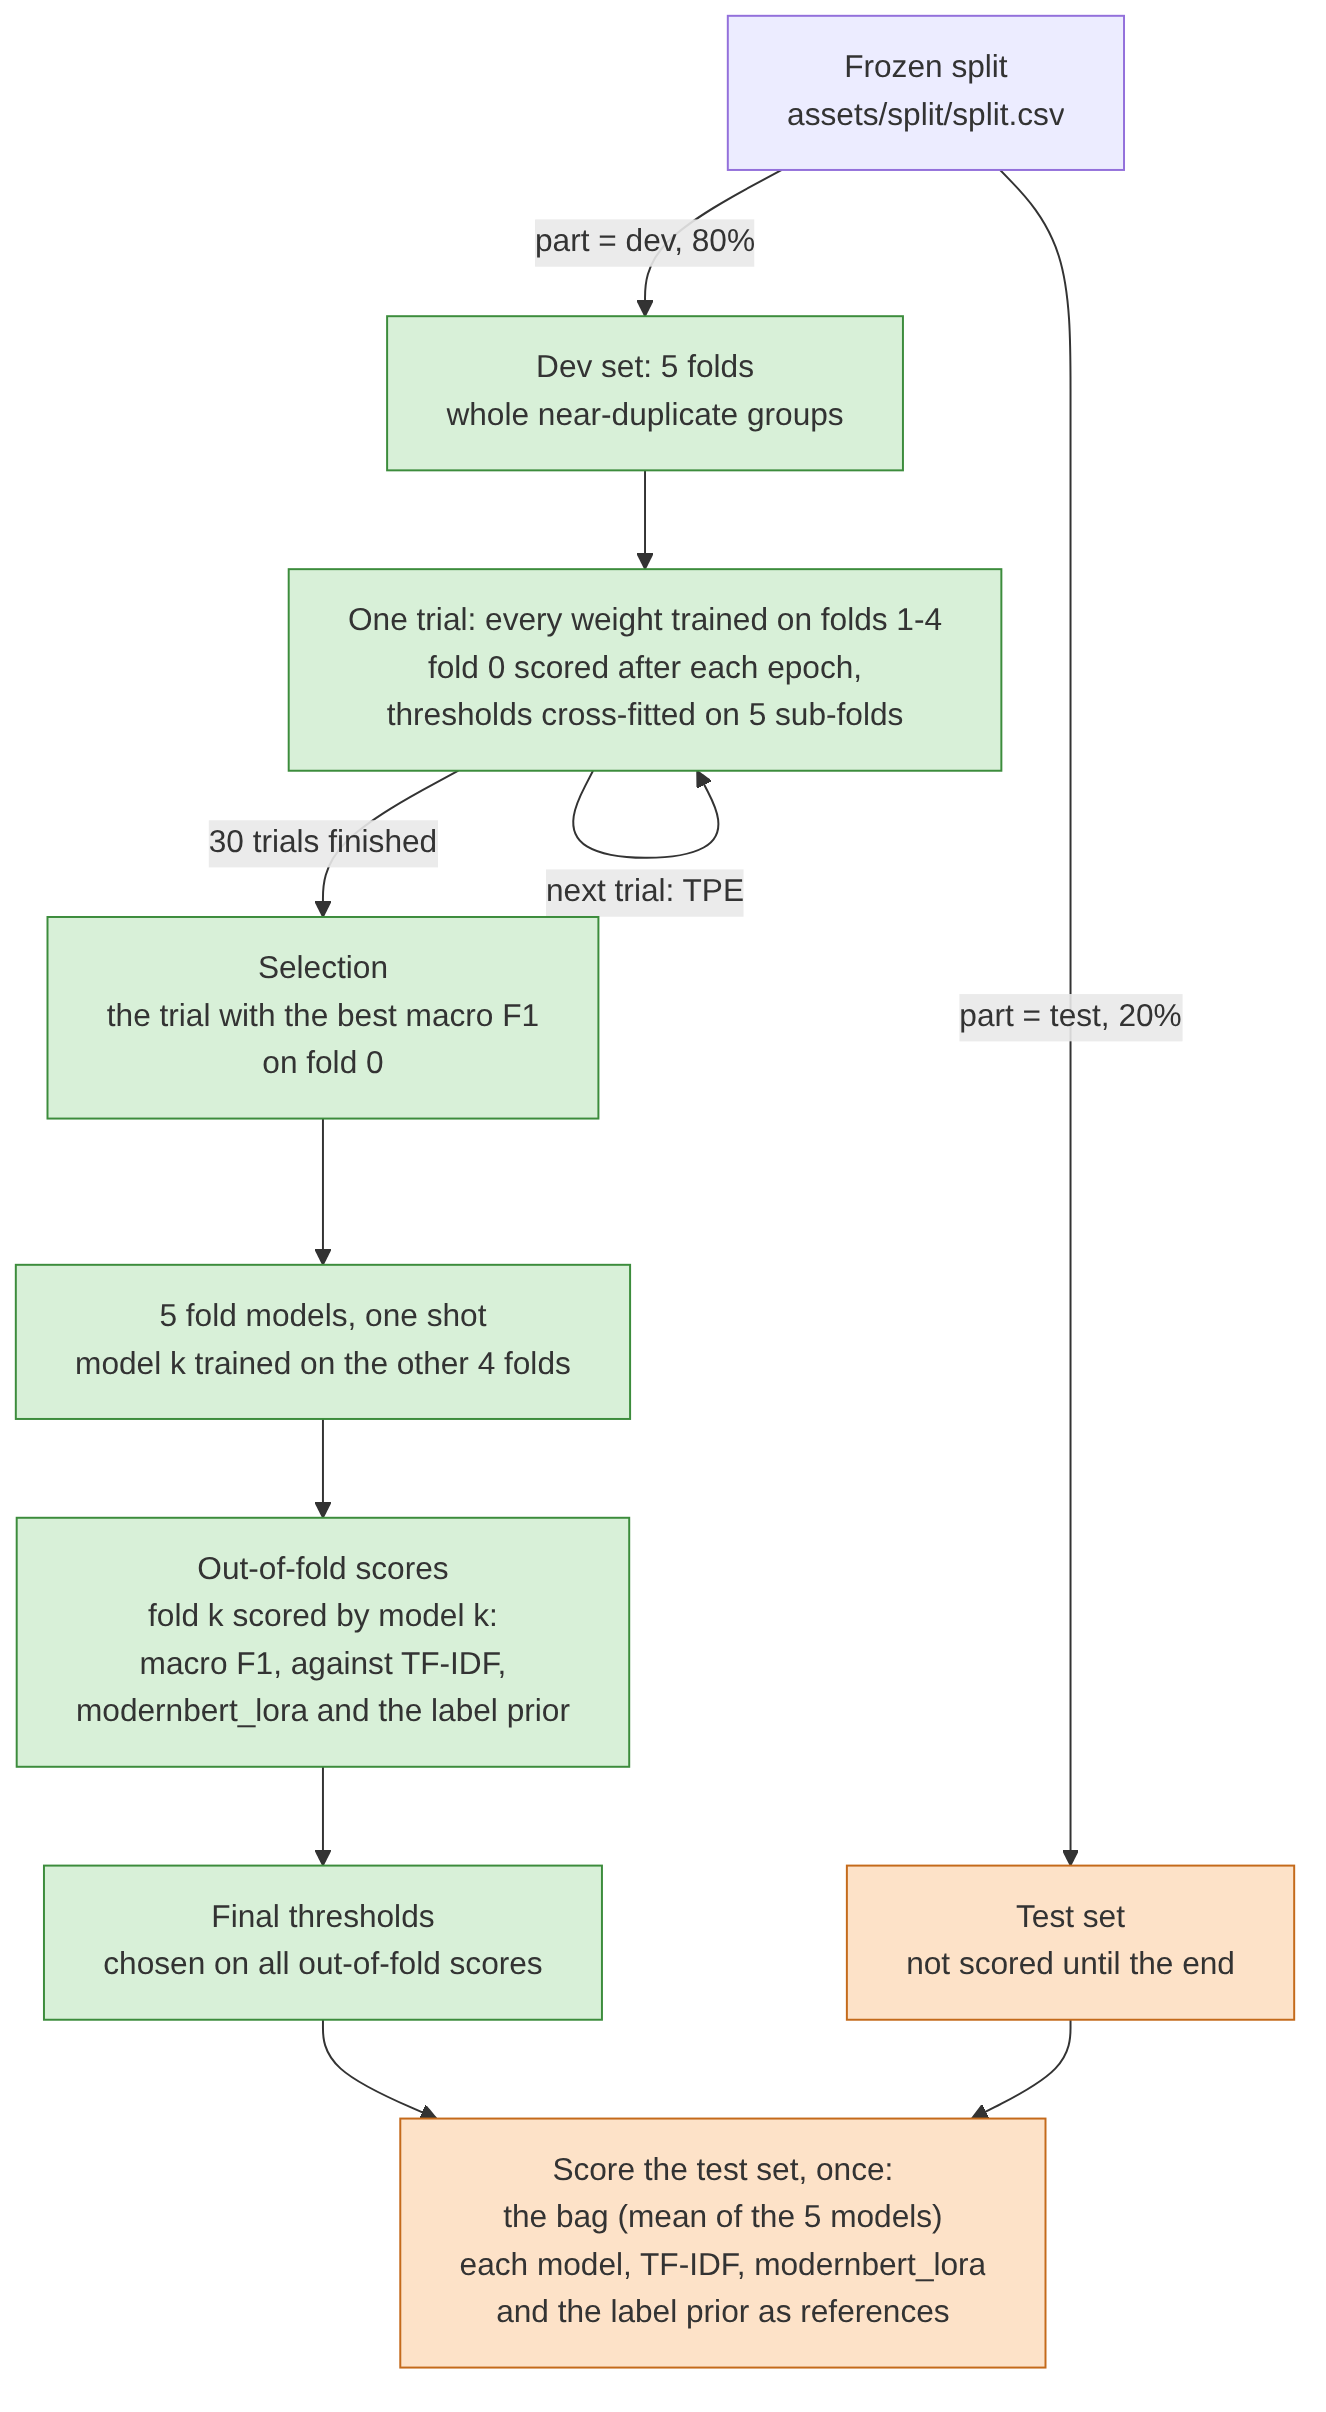

In [1]:
from IPython.display import Image

Image(filename="figures/modernbert_base_protocol.png", width=440)

## 1. Setup

The method's code lives in the package `codeforces_tags.methods.modernbert`, shared with
`modernbert_lora`: the two methods differ only in their settings (`settings.VARIANTS`), and so in
the model and how it is trained, stored and served. This notebook imports none of its training or
tuning code, nor optuna or mlflow. From the method's package it takes the settings, the input
encoding (`inputs.py`), the tokenizer and the bag's mean (`modeling.py`) and the check of the
pinned snapshot (`weights.py`). Every setting of the notebook is in the cell after the imports.

In [2]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, without ipywidgets

In [3]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from codeforces_tags.analysis.comparison import DELTA_COLUMNS, method_scores
from codeforces_tags.analysis.plotting import (
    plot_confusion_grid,
    plot_intervals,
    plot_latency,
    plot_method_f1,
    plot_study_history,
    plot_tag_confusion,
    setup_style,
)
from codeforces_tags.config import FOCUS_TAGS, LATENCY_BUDGET_S, TFIDF_TEST_MACRO_F1
from codeforces_tags.conformance import check_frozen_method
from codeforces_tags.data.labels import focus_labels
from codeforces_tags.data.loading import load_dataset
from codeforces_tags.evaluation.contamination import load_slice
from codeforces_tags.evaluation.predictions import load_predictions, load_run_record, load_scores
from codeforces_tags.evaluation.report import ALL_PROBLEMS, evaluate
from codeforces_tags.evaluation.timing import latency_summary, load_latency
from codeforces_tags.methods import method_dir, model_dir
from codeforces_tags.methods.modernbert.inputs import encode_problems, pair_budgets
from codeforces_tags.methods.modernbert.modeling import bag_mean, load_tokenizer
from codeforces_tags.methods.modernbert.settings import (
    ANALYSIS_FOLDER,
    BAG_FILE,
    CPU_LATENCY_FOLDER,
    ENCODER_FILE,
    FOLD_TEST_SCORES_FILE,
    FULL,
    HISTORY_FILE,
    IMPORTANCES_FILE,
    LORA,
    OUT_OF_FOLD_FILE,
    PARAMS_FILE,
    PRETRAINED_FILE,
    TRAINED_FILE,
    TRIALS_FILE,
    TUNING_FOLDER,
    VARIANTS,
    settings,
    study_recipe,
)
from codeforces_tags.methods.modernbert.weights import check_pretrained, snapshot_folder
from codeforces_tags.model.thresholds import (
    apply_thresholds,
    cross_fitted_predictions,
    per_tag_thresholds,
)
from codeforces_tags.splitting import load_split, release_years, select_part
from codeforces_tags.tuning.results import load_tuning_results

setup_style()

In [4]:
# The method of this notebook, and the frozen methods it is compared with.
METHOD = FULL  # modernbert_base_full
VARIANT = VARIANTS[METHOD]
LORA_METHOD = LORA  # modernbert_lora, notebook 06
PRIOR_METHOD = "label_prior"  # the F1 floor
TFIDF = "tfidf"  # the TF-IDF baseline: notebook 04's tag model, frozen by `tuning freeze`
DEV_REFERENCES = [TFIDF, LORA_METHOD, PRIOR_METHOD]

# Their frozen files: assets/methods/<name>/.
METHOD_DIR, LORA_DIR, PRIOR_DIR, TFIDF_DIR = (
    method_dir(name) for name in (METHOD, LORA_METHOD, PRIOR_METHOD, TFIDF)
)
MODEL_DIR = model_dir(METHOD)  # the method folder
TUNING_DIR = METHOD_DIR / TUNING_FOLDER  # the tuning study's results, from `export`
ANALYSIS_DIR = METHOD_DIR / ANALYSIS_FOLDER  # each fold model's test scores, CPU timings
# The latencies measured by the notebook that first trained the method, before it moved to the
# package: one fold model and the bag, with the weights swapped or the five models resident.
NOTEBOOK_LATENCY_FILE = ANALYSIS_DIR / "notebook_latency.csv"

# Section 2: the input lengths compared.
TOKEN_LIMITS = (1024, 2048, 4096)
# Section 7: the slowest CPU problems listed.
SLOWEST_SHOWN = 5

**The frozen files.** The run record pins what the method was frozen from (code, data,
environment, settings). `tuning/params.json` holds the study's chosen configuration and recipe.
The method folder `model/` holds `bag.json` (the configuration, the bag's per-tag thresholds and
its fold models) and the two weight lists, `pretrained.json` and `trained.json`, which name the
weights the method reads from its caches, with their sha256
([ADR 0006](../docs/adr/0006-trained-weight-cache.md)). `check_frozen_method` first checks that
the frozen files of the method and of the three it is compared with (`tfidf`, `modernbert_lora`
and `label_prior`) are complete and agree with the frozen split; then the method's files are
checked against each other and against the package's settings:

In [5]:
split = load_split()
for name in (METHOD, *DEV_REFERENCES):
    check_frozen_method(name, split=split)  # complete, and agreeing with the frozen split
record = load_run_record(METHOD_DIR)
entries = record.method_entries
chosen = json.loads((TUNING_DIR / PARAMS_FILE).read_text(encoding="utf-8"))
bag = json.loads((MODEL_DIR / BAG_FILE).read_text(encoding="utf-8"))
trained = json.loads((MODEL_DIR / TRAINED_FILE).read_text(encoding="utf-8"))
pretrained = json.loads((MODEL_DIR / PRETRAINED_FILE).read_text(encoding="utf-8"))
# The files describe this method, under the package's settings, with the study's chosen
# configuration.
assert record.method == METHOD and entries["settings"] == settings(VARIANT)
assert chosen["recipe"] == study_recipe(VARIANT)
assert entries["params"] == chosen["params"] == bag["params"]
assert entries["tuning"] == {"trial": chosen["trial"], "tuning_macro_f1": chosen["tuning_macro_f1"]}
print(
    f"{METHOD}: frozen on {record.created_at[:10]} at commit {record.git['commit'][:7]}, "
    f"on {entries['device']}, {entries['dtype']}; torch "
    f"{record.environment['packages']['torch']}, transformers "
    f"{record.environment['packages']['transformers']}"
)
print(
    f"supersedes: {entries['supersedes'] or 'none'}; dev scores read in sample: "
    f"{entries['dev_in_sample']}"
)
print(sorted(str(path.relative_to(METHOD_DIR)) for path in METHOD_DIR.rglob("*") if path.is_file()))

modernbert_base_full: frozen on 2026-10-07 at commit b212899, on cuda (NVIDIA GeForce RTX 2080 Ti), fp16-autocast; torch 2.14.1, transformers 5.19.0
supersedes: none; dev scores read in sample: False
['analysis/cpu/latency.csv', 'analysis/fold_test_scores.csv', 'analysis/notebook_latency.csv', 'latency.csv', 'model/bag.json', 'model/method.json', 'model/pretrained.json', 'model/trained.json', 'predictions.csv', 'run_record.json', 'scores.csv', 'tuning/history.csv', 'tuning/importances.csv', 'tuning/out_of_fold.csv', 'tuning/params.json', 'tuning/trials.csv']


## 2. The inputs: statement and solution in 2,048 tokens

The same sequence per problem as `modernbert_lora`'s, `[CLS] statement [SEP] solution [SEP]`,
with the same rule when it is too long (`inputs.py`): the solution is cut first, and keeps at
least 128 tokens. Only the limit changes, from 1,024 to 2,048 tokens. The frozen split gives the
dev set, with its 5 folds and near-duplicate groups, and the test set, which only section 6
reads.

In [6]:
problems = load_dataset()
dev = select_part(problems, split, "dev")
test = select_part(problems, split, "test")
dev_labels, test_labels = focus_labels(dev), focus_labels(test)
folds = dev["fold"]
fold_ids = sorted(folds.unique())
print(f"dev: {len(dev):,} problems in {folds.nunique()} folds; test: {len(test):,} problems")
dev_labels.groupby(folds).sum().rename_axis("dev fold")

dev: 3,988 problems in 5 folds; test: 994 problems


label,math,graphs,strings,number theory,trees,geometry,games,probabilities
dev fold,,,,,,,,
0,226,87,66,57,53,27,16,15
1,225,88,68,55,53,27,16,15
2,226,87,67,56,52,26,18,15
3,226,86,68,55,51,27,17,15
4,224,86,68,55,52,26,17,14


**How long are the inputs?** The share of dev problems a length limit keeps whole, under the
method's rule (`inputs.pair_budgets`), counted with the method's pinned tokenizer:

In [7]:
snapshot = check_pretrained(pretrained)  # the pinned snapshot, every file's sha256 checked
tokenizer = load_tokenizer(snapshot)
token_counts = pd.DataFrame(
    {
        column: [
            len(ids)
            for ids in tokenizer(dev[field].tolist(), add_special_tokens=False)["input_ids"]
        ]
        for column, field in (("statement", "statement"), ("solution", "source_code"))
    },
    index=dev.index,
)
# The tokens each part keeps under each limit, by the method's rule (inputs.pair_budgets).
kept = {
    limit: pd.DataFrame(
        [
            pair_budgets(statement, solution, limit, VARIANT.code_min_tokens)
            for statement, solution in zip(
                token_counts["statement"], token_counts["solution"], strict=True
            )
        ],
        index=dev.index,
        columns=token_counts.columns,
    )
    for limit in TOKEN_LIMITS
}
pd.DataFrame(
    {
        "statement whole": [
            (kept[limit]["statement"] == token_counts["statement"]).mean() for limit in TOKEN_LIMITS
        ],
        "statement and solution whole": [
            (kept[limit] == token_counts).all(axis=1).mean() for limit in TOKEN_LIMITS
        ],
    },
    index=pd.Index(TOKEN_LIMITS, name="max tokens"),
).round(3)

,statement whole,statement and solution whole
max tokens,,
1024,0.984,0.737
2048,1.000,0.958
4096,1.000,0.992


**Why 2,048 tokens.** Training every weight of the base model costs about 45 ms per problem
padded to 1,024 tokens and 112 ms padded to 2,048 (measured before the study, fp16, batches of 8
and 4), against 104 ms at 1,024 tokens for LoRA on the large model. Doubling the limit keeps 96%
of problems whole instead of 74%, so the longer solutions are read to the end. Three problems in
four are shorter than 1,024 tokens, and batches group problems of similar length, so most
batches cost what they would at 1,024 tokens, under half of what `modernbert_lora` pays per
problem: a training epoch still costs less than `modernbert_lora`'s. The inputs, as the method
encodes them (`inputs.encode_problems`):

In [8]:
dev_ids = encode_problems(dev, tokenizer, VARIANT.max_length, VARIANT.code_min_tokens)
input_tokens = pd.Series([len(ids) for ids in dev_ids], index=dev.index, name="input tokens")
print(
    f"longest dev input: {input_tokens.max():,} tokens; "
    f"{(input_tokens == VARIANT.max_length).sum()} dev problems fill all "
    f"{VARIANT.max_length:,}"
)

longest dev input: 2,048 tokens; 169 dev problems fill all 2,048


## 3. The model and its training

The code is the package's; this section says what it does, and where.

**The model** (`modeling.classifier_model`). ModernBERT-base with a classification head of one
output per focus tag, and every one of its 150M weights trained: the encoder, its pooling head
(`head`: dense, activation, norm) and the new `classifier`, with dropout before it
(`classifier_dropout`, tuned). Attention runs through PyTorch's SDPA kernels, as for
`modernbert_lora`.

**The loss** (`training.WeightedBce`) is `modernbert_lora`'s: binary cross-entropy per tag, each
tag's positives weighted by `(negatives / positives) ** pos_weight_power`
(`training.positive_weights`).

**Training** (`training.train_model`, `training.training_arguments`). The Hugging Face `Trainer`,
set up as for `modernbert_lora`: fp16 mixed precision, 4 problems per forward pass and 4 or 8
passes per optimiser step (batch 16 or 32), length-grouped batches, linear warmup then linear
decay, and no checkpoint, evaluation or report of the `Trainer`'s own (its checkpoints hold
pickle files). Two settings differ:
- **AdamW over every weight**, with the weight decay tuned (the `Trainer` leaves biases and
  normalisation weights out of the decay); the optimiser's state (two float32 copies of every
  weight) is what makes full fine-tuning heavier in memory than LoRA;
- **the learning rates are lower**: from 1e-5 to 2e-4, against 5e-5 to 1e-3 for LoRA, whose
  updates start at zero.

**Scoring** (`modeling.predict_scores`): batches of similar length, fp16 autocast on the GPU
(float32 on the CPU), the probability of each tag. The bag (`modeling.FullBag`) holds one model
and every fold model's weights, and copies each set into the model before its forward pass; its
score is the mean of the five probabilities (`modeling.bag_mean`). `method.py` makes it a score
method of the framework: `predict` preprocesses raw problems (`raw_to_problems`), encodes and
scores them, and predicts each tag whose score reaches the bag's threshold.

The method's settings (`settings.VARIANTS["modernbert_base_full"]`), as its run record holds them;
the `retrain_*` settings are the bounds that `verify --retrain` must meet
([ADR 0005](../docs/adr/0005-fine-tuned-model-protocol.md)):

In [9]:
# Every setting of the method but the search space (section 4) and the LoRA-only ones.
LORA_ONLY = ("lora_targets", "trained_modules", "lora_alpha_per_rank", "weight_decay")
pd.Series(
    {
        name: value
        for name, value in settings(VARIANT).items()
        if name != "search_space" and name not in LORA_ONLY
    },
    name=METHOD,
    dtype=object,
).to_frame()

,modernbert_base_full
name,modernbert_base_full
study_name,modernbert-base-full
model_repo,answerdotai/ModernBERT-base
model_revision,8949b909ec900327062f0ebf497f51aef5e6f0c8
lora,False
max_length,2048
code_min_tokens,128
micro_batch,4
score_batch,16
pad_to_multiple_of,8


## 4. The tuning study, on one fold

`modernbert_lora`'s study, with the same objective and protocol (`tuning.py`): a trial trains on
dev folds 1-4 (3,182 problems) and scores fold 0 (806 problems) after each epoch; the objective is
fold 0's macro F1 after the last epoch, with per-tag thresholds cross-fitted across 5 stratified
group sub-folds of fold 0; TPE after 10 random trials; a trial is pruned below the median of the
trials of its epoch count, at an epoch. As for `modernbert_lora`, fold 0's model in section 5
retrains the configuration chosen on fold 0 (not bit for bit: GPU training is not
bit-reproducible), so section 5 also reports the out-of-fold score of folds 1-4 alone.

**Where it comes from.** The study ran in the notebook that first trained the method (this
notebook, numbered 06, before the methods moved to the package), with the code that is now
`tuning.py`, about 3.6 hours on an RTX 2080 Ti. `export` froze its results from that run's
journal in `assets/methods/modernbert_base_full/tuning/`, reading it without writing to it; no
command re-runs it (`tune` would resume it from `experiments/modernbert_base_full/optuna.jsonl`).

**The search** has 7 dimensions, those of full fine-tuning (`VARIANT.search_space`):

| Parameter | Range | Why |
|---|---|---|
| `learning_rate` | 1e-5 to 2e-4, log scale | around the usual 1e-5 to 1e-4 for fine-tuning every weight of an encoder (ModernBERT's own GLUE sweep: 1e-5 to 8e-5), widened to find where full fine-tuning in fp16 breaks |
| `weight_decay` | 1e-5 to 0.1, log scale | regularises the weights (not the biases or normalisation weights); with about 3,200 training problems a 150M-parameter model can overfit |
| `classifier_dropout` | 0 to 0.2 | regularises the new head |
| `epochs` | 2 to 5 | fixed for a configuration: no early stopping on the scored fold |
| `batch_size` | 16, 32 | problems per optimiser step (4 per pass, 4 or 8 passes) |
| `warmup_ratio` | 0 to 0.2 | share of the steps with a rising learning rate |
| `pos_weight_power` | 0 to 1 | how much the loss favours each tag's positives |

**The trials** (`tuning/trials.csv`, `tuning/history.csv`). `value` is the scored fold's macro
F1 after the last epoch the trial ran (`epochs_run`: for a pruned trial, the epoch it was stopped
at), `first_epoch_f1` the same after its first epoch, `macro_ap` its macro average precision at
the end:

In [10]:
trials = pd.read_csv(TUNING_DIR / TRIALS_FILE, float_precision="round_trip")
history = pd.read_csv(TUNING_DIR / HISTORY_FILE, float_precision="round_trip")
states = trials["state"].value_counts()
print(
    f"{states.get('COMPLETE', 0)} complete, {states.get('PRUNED', 0)} pruned, "
    f"{states.get('FAIL', 0)} failed; {trials['minutes'].sum() / 60:.1f} hours of training"
)
complete = trials[trials["state"] == "COMPLETE"]
best_ten = complete.nlargest(10, "value")
print(
    f"the ten best complete trials: macro F1 {best_ten['value'].min():.3f} to "
    f"{best_ten['value'].max():.3f}, {(best_ten['batch_size'] == 32).sum()} of them at batch 32"
)
# Every trial, with its scored fold's macro F1 after the first epoch; learning rate and weight
# decay in scientific notation.
first_epoch = history[history["epoch"] == 1].set_index("number")["macro_f1"]
trials.set_index("number").assign(
    first_epoch_f1=first_epoch,
    learning_rate=trials.set_index("number")["learning_rate"].map("{:.2e}".format),
    weight_decay=trials.set_index("number")["weight_decay"].map("{:.1e}".format),
)[
    [
        "state",
        "value",
        "epochs",
        "epochs_run",
        "first_epoch_f1",
        "macro_ap",
        "learning_rate",
        "batch_size",
        "warmup_ratio",
        "weight_decay",
        "classifier_dropout",
        "pos_weight_power",
        "minutes",
    ]
].round(3)

17 complete, 13 pruned, 0 failed; 3.6 hours of training
the ten best complete trials: macro F1 0.637 to 0.665, 9 of them at batch 32


,state,value,epochs,epochs_run,first_epoch_f1,macro_ap,learning_rate,batch_size,warmup_ratio,weight_decay,classifier_dropout,pos_weight_power,minutes
number,,,,,,,,,,,,,
0,COMPLETE,0.637,4,4,0.305,0.686,5.18e-05,32,0.088,7.3e-03,0.121,0.892,10.018
1,COMPLETE,0.641,4,4,0.403,0.666,1.79e-04,32,0.014,3.4e-04,0.158,0.087,10.306
2,COMPLETE,0.579,5,5,0.278,0.641,1.06e-05,16,0.092,2.1e-02,0.156,0.781,13.087
3,COMPLETE,0.640,5,5,0.325,0.684,1.43e-05,16,0.053,3.6e-03,0.029,0.774,13.139
4,COMPLETE,0.642,4,4,0.329,0.689,3.92e-05,32,0.189,1.9e-03,0.004,0.682,10.457
5,COMPLETE,0.421,2,2,0.279,0.419,2.94e-05,32,0.042,5.6e-04,0.140,0.129,5.248
6,COMPLETE,0.635,3,3,0.426,0.690,2.57e-05,16,0.042,2.8e-04,0.114,0.161,7.933
7,COMPLETE,0.538,2,2,0.375,0.575,7.07e-05,16,0.131,1.0e-04,0.093,0.138,5.301
8,COMPLETE,0.492,2,2,0.372,0.523,1.80e-05,16,0.195,3.0e-04,0.164,0.469,5.307


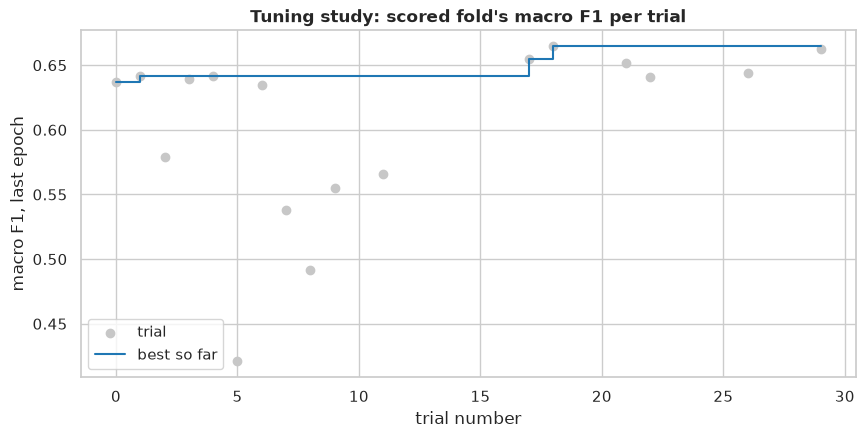

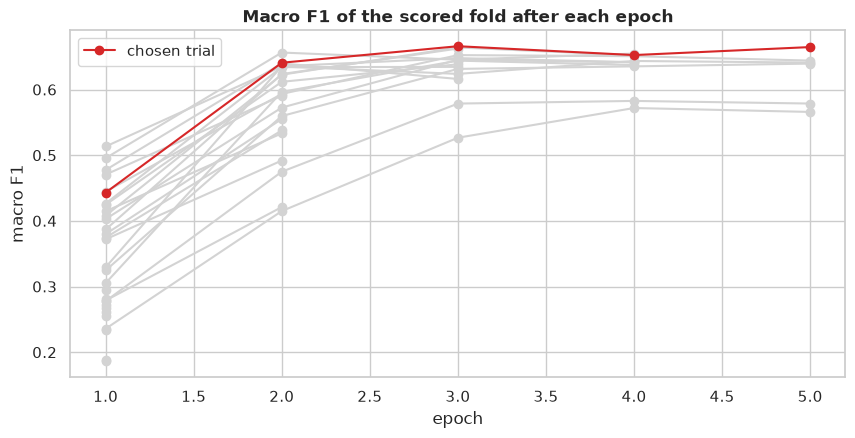

In [11]:
ax = plot_study_history(trials)
ax.set(title="Tuning study: scored fold's macro F1 per trial", ylabel="macro F1, last epoch")
plt.show()
_, ax = plt.subplots()
for number, curve in history.groupby("number"):
    is_chosen = number == chosen["trial"]
    ax.plot(
        curve["epoch"],
        curve["macro_f1"],
        marker="o",
        color="C3" if is_chosen else "lightgrey",
        zorder=2 if is_chosen else 1,
        label="chosen trial" if is_chosen else None,
    )
ax.set(title="Macro F1 of the scored fold after each epoch", xlabel="epoch", ylabel="macro F1")
ax.legend()
plt.show()

**Which parameters matter.** fANOVA importances (seeded) of the complete trials
(`tuning/importances.csv`), rough with a few dozen trials:

In [12]:
pd.read_csv(TUNING_DIR / IMPORTANCES_FILE, index_col="parameter").round(3)

,importance
parameter,
epochs,0.521
classifier_dropout,0.220
pos_weight_power,0.107
learning_rate,0.058
weight_decay,0.043
warmup_ratio,0.033
batch_size,0.019


In [13]:
tuning_fold_scores = pd.read_csv(
    TUNING_DIR / OUT_OF_FOLD_FILE, index_col="metric", float_precision="round_trip"
)["value"]
best_trial = complete.loc[complete["value"].idxmax()]
assert best_trial["number"] == chosen["trial"]
assert best_trial["value"] == chosen["tuning_macro_f1"] == tuning_fold_scores["macro_f1"]
print(
    f"chosen: trial {chosen['trial']}, scored fold's macro F1 {chosen['tuning_macro_f1']:.4f} "
    f"(macro AP {tuning_fold_scores['macro_ap']:.4f})"
)
pd.Series(chosen["params"], name="chosen", dtype=object).to_frame()

chosen: trial 18, scored fold's macro F1 0.6647 (macro AP 0.6698)


,chosen
learning_rate,0.000093
weight_decay,0.000756
classifier_dropout,0.06932
epochs,5
batch_size,32
warmup_ratio,0.167986
pos_weight_power,0.610089


The chosen trial's macro F1 is the best of 30 noisy scores on the fold they were all chosen on,
so it overstates what the configuration does on new problems; section 5's out-of-fold score on
folds 1-4 does not have this bias.

**What the study shows**
- **Full fine-tuning needs more passes.** The four trials of 2 epochs scored 0.42 to 0.56, and
  the epoch count explains half of the variance across the complete trials (fANOVA, 0.52); the
  chosen trial runs 5 epochs, the top of the range, where `modernbert_lora`'s ran 2 (notebook 06).
  A plateau again: the ten best complete trials score between 0.637 and 0.665, nine of them at
  batch 32.
- **One fold is a noisy judge, again.** Trial 22 is a near copy of the chosen trial 18 (nearly
  the same learning rate, 9.24e-5 against 9.25e-5, 5 epochs, batch 32, a close weight decay,
  dropout and weight power, a shorter warmup) and scores 0.641 against 0.665, a gap of 0.024
  like the 0.026 of `modernbert_lora`'s study (notebook 06).
- **Fewer collapses than LoRA.** No complete trial ended at the base rate. Three trials (14, 19
  and 28), at learning rates of 1.3e-4 to 1.5e-4, were near it after one epoch (macro F1 0.19
  to 0.23) and were pruned there, while trials 17 and 1 trained well at 1.4e-4 and 1.8e-4; none
  of the five fold models of section 5 collapsed.
- **Pruning after one epoch favours fast starters.** Trials 0 and 4 scored 0.305 and 0.329 after
  their first epoch and ended at 0.637 and 0.642, among the ten best, while trials 16, 23 and
  24, whose warmup took 17% to 20% of the steps, were pruned at 0.26 to 0.29 after theirs: with
  full fine-tuning the first epoch says little, and a long warmup makes it say less. A next
  study should not prune before the warmup ends, or before half the epochs.

## 5. Five fold models with the chosen configuration

The chosen configuration trains one fold model per dev fold k, on the four other folds, with
nothing tuned again (`training.train_fold_model`, `folds.train_folds`). As for `modernbert_lora`,
a model whose training collapsed (a macro average precision under 0.3 on 800 of its own training
problems) would be trained again with the next seed; none did.

**Where they come from.** The five fold models were trained by the notebook that first trained
the method, with the code that is now `training.py`, in 1.1 hours, each with the first seed.
`adopt` copied them into the trained cache, `experiments/trained/modernbert_base_full/`, after
checking their recipe and configuration, and `trained.json` pins each one by its sha256
([ADR 0006](../docs/adr/0006-trained-weight-cache.md)): each is a whole model of 571 MiB in
float32, too large to commit. The run record keeps each fold model's training record:

In [14]:
fold_models = pd.DataFrame.from_dict(entries["fold_models"], orient="index").join(
    pd.DataFrame.from_dict(trained["folds"], orient="index")[["bytes", "sha256"]]
)
fold_models["sha256"] = fold_models["sha256"].str[:12] + "..."
print(
    f"{len(fold_models)} fold models, {fold_models['minutes'].sum() / 60:.1f} hours of training; "
    f"seeds that collapsed: {sum(len(seeds) for seeds in fold_models['collapsed_seeds'])}"
)
fold_models.rename_axis("fold model").round(3)

5 fold models, 1.1 hours of training; seeds that collapsed: 0


,seed,collapsed_seeds,train_macro_ap,minutes,adopted_from,bytes,sha256
fold model,,,,,,,
fold_0,0,[],0.986,12.522,experiments/modernbert_base_full/models/fold_0,598458240,d4065d128c49...
fold_1,0,[],0.984,13.072,experiments/modernbert_base_full/models/fold_1,598458240,45a570561e04...
fold_2,0,[],0.965,13.258,experiments/modernbert_base_full/models/fold_2,598458240,7838f95e458c...
fold_3,0,[],0.973,12.802,experiments/modernbert_base_full/models/fold_3,598458240,d9b6f93da233...
fold_4,0,[],0.996,12.551,experiments/modernbert_base_full/models/fold_4,598458240,73b16f5a3b93...


**Out of fold.** The dev rows of `scores.csv` are each fold's scores by its own fold model, and
the dev rows of `predictions.csv` are those scores with per-tag thresholds chosen on the other
four folds' scores. `freeze` derived them from the scores each fold model saved after training,
and checked that every fold model, loaded from the method folder, gives its fold's scores back;
`verify` re-scored each dev fold the same way. The largest gap was 0.00e+00 both times, on the
GPU that froze the method (`verify` prints it; this notebook loads no model). Here the dev
predictions are derived again from the frozen scores:

In [15]:
predictions = load_predictions(METHOD_DIR)
scores = load_scores(METHOD_DIR)
dev_scores = scores.loc["dev"].loc[dev.index]
dev_predictions = predictions.loc["dev"].loc[dev.index]
print(f"dev rows, as the run record describes them: {entries['dev_estimate']}")
# The frozen dev rows again: each fold's scores with the thresholds cross-fitted on the others.
fold_thresholds, rederived = cross_fitted_predictions(dev_scores, dev_labels, folds)
print(
    "dev predictions re-derived from the frozen scores, cells that differ: "
    f"{int((rederived.to_numpy() != dev_predictions.to_numpy()).sum())}"
)
assert np.array_equal(rederived.to_numpy(), dev_predictions.to_numpy())
print("Thresholds of each fold, chosen on the other folds' out-of-fold scores:")
fold_thresholds.rename_axis("dev fold").round(3)

dev rows, as the run record describes them: Each dev problem is scored by the fold model that did not train on it, and predicted with thresholds cross-fitted across the dev folds. The bag scores test only, so the dev rows estimate one fold model, not the bag.
dev predictions re-derived from the frozen scores, cells that differ: 0
Thresholds of each fold, chosen on the other folds' out-of-fold scores:


,math,graphs,strings,number theory,trees,geometry,games,probabilities
dev fold,,,,,,,,
0,0.213,0.538,0.547,0.475,0.815,0.315,0.946,0.557
1,0.230,0.538,0.547,0.559,0.680,0.315,0.946,0.874
2,0.229,0.537,0.208,0.480,0.680,0.334,0.946,0.874
3,0.229,0.538,0.591,0.475,0.326,0.242,0.946,0.886
4,0.275,0.538,0.564,0.475,0.841,0.315,0.790,0.557


**Against the references, paired.** The same dev problems, predicted out of fold by three
references:
- `tfidf`, the TF-IDF baseline of notebook 04, from its frozen dev predictions, whose macro F1
  is checked against notebook 04's tuning study;
- `modernbert_lora`, from its frozen dev predictions, made like this method's;
- `label_prior`, the F1 floor, from its frozen dev predictions.

Choosing between the methods is done on these dev scores
([ADR 0004](../docs/adr/0004-tagging-method-framework.md),
[ADR 0005](../docs/adr/0005-fine-tuned-model-protocol.md)); every comparison goes through
`analysis.comparison.method_scores`, with the same group bootstrap resamples for every method:

In [16]:
tfidf_predictions = load_predictions(TFIDF_DIR)
lora_predictions = load_predictions(LORA_DIR)
prior_predictions = load_predictions(PRIOR_DIR)
dev_by_method = {
    name: frame.loc[dev.index, list(dev_labels.columns)]
    for name, frame in {
        METHOD: dev_predictions,
        TFIDF: tfidf_predictions.loc["dev"],
        LORA_METHOD: lora_predictions.loc["dev"],
        PRIOR_METHOD: prior_predictions.loc["dev"],
    }.items()
}
# The frozen method is notebook 04's model, to the last digit.
assert (
    evaluate(dev_labels, dev_by_method[TFIDF]).macro_f1
    == load_tuning_results().out_of_fold.at["macro_f1", "f1"]
)
oof = evaluate(dev_labels, dev_predictions, release_years=release_years(dev), groups=dev["group"])
print(
    "out-of-fold macro F1: "
    + ", ".join(
        f"{name} {evaluate(dev_labels, predicted).macro_f1:.4f}"
        for name, predicted in dev_by_method.items()
    )
)
oof.summary.round(3)

out-of-fold macro F1: modernbert_base_full 0.6530, tfidf 0.6629, modernbert_lora 0.6611, label_prior 0.1485


,problems,macro_f1,micro_f1,no_focus_nothing_predicted,macro_f1_low,macro_f1_high,micro_f1_low,micro_f1_high
slice,,,,,,,,
all problems,3988,0.653,0.611,0.557,0.632,0.671,0.596,0.625
focus-tagged,2143,0.724,0.720,NaN,0.703,0.743,0.705,0.733
up to 2017,1626,0.654,0.575,0.650,0.621,0.683,0.550,0.600
from 2018,2362,0.644,0.629,0.471,0.613,0.668,0.611,0.647


Out of fold, F1 of each method (group bootstrap intervals in the figure):


method,modernbert_base_full,tfidf,modernbert_lora,label_prior
metric,,,,
macro_f1,0.653,0.663,0.661,0.149
micro_f1,0.611,0.617,0.628,0.158
math,0.578,0.582,0.611,0.441
graphs,0.623,0.603,0.602,0.196
strings,0.636,0.690,0.665,0.156
number theory,0.596,0.541,0.585,0.130
trees,0.654,0.719,0.650,0.123
geometry,0.658,0.652,0.683,0.065
games,0.756,0.835,0.750,0.041


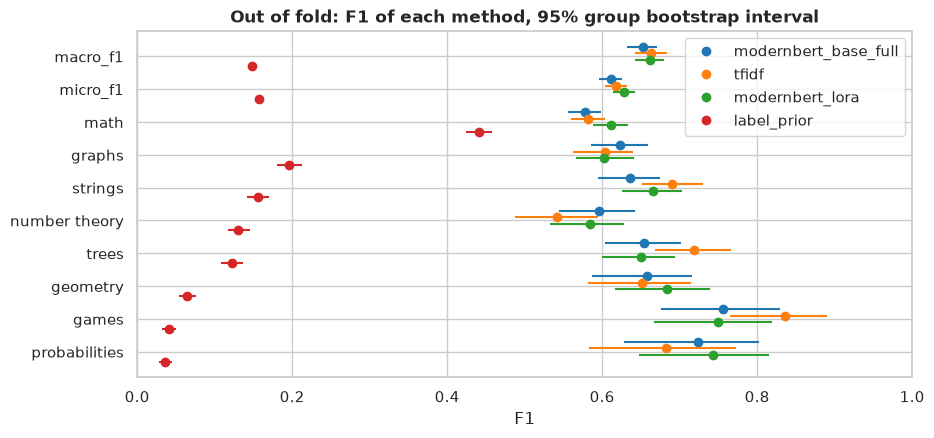

In [17]:
METRICS = ["macro_f1", "micro_f1", *FOCUS_TAGS]
dev_table = method_scores(dev_labels, dev_by_method, dev["group"])
print("Out of fold, F1 of each method (group bootstrap intervals in the figure):")
display(
    dev_table["f1"].unstack("method").reindex(index=METRICS, columns=list(dev_by_method)).round(3)
)
ax = plot_method_f1(dev_table)
ax.set(title="Out of fold: F1 of each method, 95% group bootstrap interval")
plt.show()

In [18]:
print(f"Out of fold, {METHOD} minus each reference (paired group bootstrap):")
display(
    pd.concat(
        {
            reference: method_scores(
                dev_labels,
                {reference: dev_by_method[reference], METHOD: dev_by_method[METHOD]},
                dev["group"],
                baseline=reference,
            ).loc[METHOD, list(DELTA_COLUMNS)]
            for reference in DEV_REFERENCES
        },
        axis=1,
    ).round(3)
)
print(f"For the per-tag picture, {LORA_METHOD} minus {TFIDF} (paired group bootstrap):")
method_scores(
    dev_labels,
    {TFIDF: dev_by_method[TFIDF], LORA_METHOD: dev_by_method[LORA_METHOD]},
    dev["group"],
    baseline=TFIDF,
).loc[LORA_METHOD, list(DELTA_COLUMNS)].round(3)

Out of fold, modernbert_base_full minus each reference (paired group bootstrap):


tfidf                      modernbert_lora            \
               delta delta_low delta_high           delta delta_low   
metric                                                                
macro_f1      -0.010    -0.027      0.007          -0.008    -0.024   
micro_f1      -0.006    -0.019      0.006          -0.017    -0.029   
math          -0.004    -0.024      0.014          -0.034    -0.053   
graphs         0.020    -0.014      0.053           0.020    -0.010   
strings       -0.054    -0.083     -0.026          -0.029    -0.059   
number theory  0.055     0.008      0.103           0.012    -0.030   
trees         -0.064    -0.103     -0.028           0.005    -0.034   
geometry       0.006    -0.052      0.063          -0.026    -0.079   
games         -0.079    -0.147     -0.014           0.006    -0.056   
probabilities  0.042    -0.030      0.113          -0.019    -0.084   

                         label_prior                       
              delta_high       delta delta_low delta_high  
metric                                                     
macro_f1           0.007       0.504     0.483      0.522  
micro_f1          -0.005       0.453     0.440      0.466  
math              -0.015       0.137     0.118      0.155  
graphs             0.049       0.426     0.391      0.461  
strings            0.001       0.480     0.444      0.515  
number theory      0.054       0.466     0.415      0.513  
trees              0.044       0.531     0.480      0.579  
geometry           0.026       0.593     0.528      0.650  
games              0.070       0.715     0.637      0.785  
probabilities      0.041       0.687     0.593      0.765

For the per-tag picture, modernbert_lora minus tfidf (paired group bootstrap):


,delta,delta_low,delta_high
metric,,,
macro_f1,-0.002,-0.018,0.014
micro_f1,0.011,-0.002,0.023
math,0.029,0.010,0.050
graphs,-0.001,-0.030,0.031
strings,-0.025,-0.055,0.006
number theory,0.043,-0.008,0.090
trees,-0.069,-0.109,-0.034
geometry,0.032,-0.027,0.094
games,-0.085,-0.154,-0.019


,support,tp,fp,fn,precision,recall,f1,f1_low,f1_high
tag,,,,,,,,,
math,1127,812,873,315,0.482,0.720,0.578,0.555,0.599
graphs,434,260,141,174,0.648,0.599,0.623,0.586,0.659
strings,337,239,176,98,0.576,0.709,0.636,0.595,0.674
number theory,278,158,94,120,0.627,0.568,0.596,0.545,0.643
trees,261,158,64,103,0.712,0.605,0.654,0.604,0.702
geometry,133,96,63,37,0.604,0.722,0.658,0.587,0.716
games,84,59,13,25,0.819,0.702,0.756,0.676,0.829
probabilities,74,51,16,23,0.761,0.689,0.723,0.629,0.803


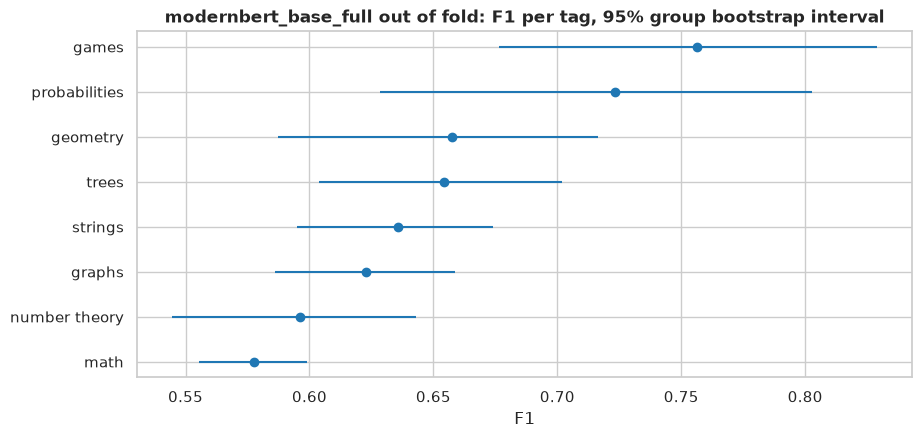

In [19]:
oof_per_tag = oof.per_tag.loc[ALL_PROBLEMS]
display(
    oof_per_tag[
        ["support", "tp", "fp", "fn", "precision", "recall", "f1", "f1_low", "f1_high"]
    ].round(3)
)
ax = plot_intervals(oof_per_tag.sort_values("f1", ascending=False), "f1", "f1_low", "f1_high")
ax.set(title=f"{METHOD} out of fold: F1 per tag, 95% group bootstrap interval", xlabel="F1")
plt.show()

**Without the tuning fold.** Fold 0's model retrains the configuration chosen on fold 0 as the
best of 30, so fold 0's out-of-fold score carries the study's selection; folds 1-4 carry none.
The same comparison on folds 1-4 alone (the run record keeps this method's score there as
`outside_tuning_fold_macro_f1`), then each fold:

In [20]:
outside = (folds != VARIANT.tuning_fold).to_numpy()
outside_f1 = evaluate(dev_labels[outside], dev_predictions[outside]).macro_f1
assert outside_f1 == entries["outside_tuning_fold_macro_f1"]  # as the run record holds it
print(f"Folds other than {VARIANT.tuning_fold}, {METHOD} minus each reference (paired):")
display(
    pd.concat(
        {
            reference: method_scores(
                dev_labels[outside],
                {
                    reference: dev_by_method[reference][outside],
                    METHOD: dev_by_method[METHOD][outside],
                },
                dev.loc[outside, "group"],
                baseline=reference,
            ).loc[METHOD, ["f1", *DELTA_COLUMNS]]
            for reference in DEV_REFERENCES
        },
        axis=1,
    ).round(3)
)
pd.DataFrame(
    {
        "problems": folds.value_counts().sort_index(),
        **{
            name: [
                evaluate(dev_labels[folds == fold], predicted[folds == fold]).macro_f1
                for fold in fold_ids
            ]
            for name, predicted in dev_by_method.items()
        },
    }
).rename_axis("dev fold").round(3)

Folds other than 0, modernbert_base_full minus each reference (paired):


tfidf                             modernbert_lora         \
                  f1  delta delta_low delta_high              f1  delta   
metric                                                                    
macro_f1       0.651 -0.011    -0.031      0.008           0.651 -0.011   
micro_f1       0.605 -0.013    -0.027      0.001           0.605 -0.023   
math           0.573 -0.012    -0.033      0.007           0.573 -0.038   
graphs         0.598  0.010    -0.031      0.050           0.598  0.002   
strings        0.626 -0.058    -0.092     -0.023           0.626 -0.042   
number theory  0.602  0.049    -0.003      0.101           0.602  0.013   
trees          0.645 -0.080    -0.125     -0.038           0.645 -0.008   
geometry       0.644  0.018    -0.046      0.079           0.644 -0.016   
games          0.778 -0.082    -0.167     -0.009           0.778  0.019   
probabilities  0.743  0.064    -0.010      0.153           0.743 -0.018   

                                   label_prior                              
              delta_low delta_high          f1  delta delta_low delta_high  
metric                                                                      
macro_f1         -0.030      0.008       0.651  0.503     0.479      0.522  
micro_f1         -0.038     -0.010       0.605  0.447     0.431      0.462  
math             -0.059     -0.018       0.573  0.132     0.111      0.153  
graphs           -0.033      0.035       0.598  0.402     0.357      0.444  
strings          -0.074     -0.007       0.626  0.469     0.427      0.510  
number theory    -0.033      0.060       0.602  0.472     0.418      0.526  
trees            -0.049      0.036       0.645  0.522     0.468      0.575  
geometry         -0.078      0.044       0.644  0.580     0.510      0.640  
games            -0.056      0.096       0.778  0.736     0.647      0.811  
probabilities    -0.090      0.059       0.743  0.707     0.612      0.794

,problems,modernbert_base_full,tfidf,modernbert_lora,label_prior
dev fold,,,,,
0,806,0.661,0.665,0.655,0.148
1,790,0.657,0.661,0.661,0.150
2,797,0.632,0.652,0.661,0.149
3,795,0.629,0.656,0.644,0.149
4,800,0.684,0.681,0.682,0.147


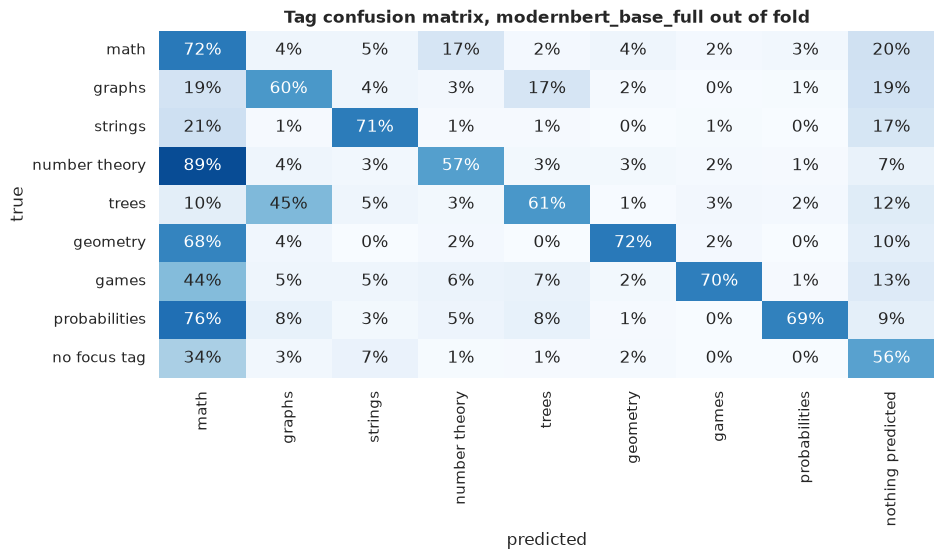

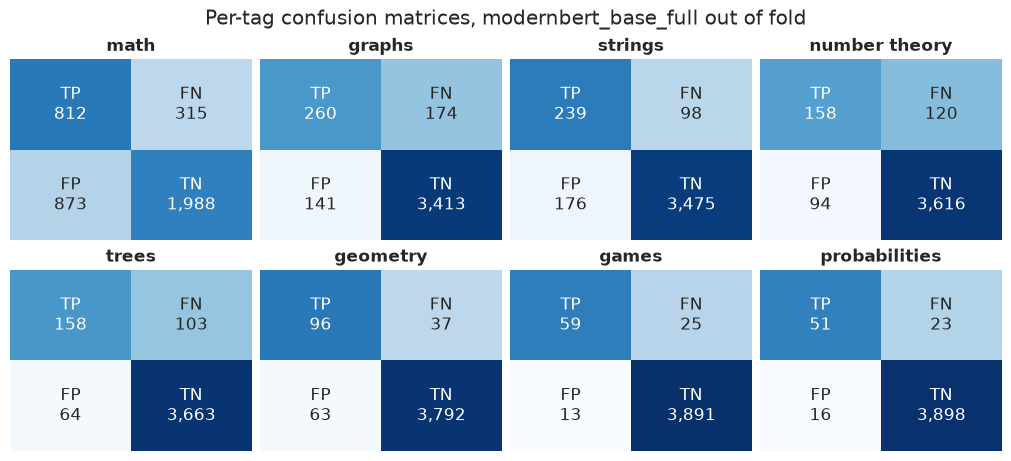

In [21]:
ax = plot_tag_confusion(oof.tag_confusion)
ax.set(title=f"Tag confusion matrix, {METHOD} out of fold")
plt.show()
figure = plot_confusion_grid(oof_per_tag)
figure.suptitle(f"Per-tag confusion matrices, {METHOD} out of fold")
plt.show()

**Without the self-identifying solutions.** A solution that names or quotes its own problem (a
Codeforces URL, a contest id, copied statement text) could let a model recognise a problem rather
than read it. The frozen slice of these problems (`assets/slices/self_identifying_solutions.csv`)
is left out:

In [22]:
self_identifying = load_slice()
dev_kept = ~dev.index.isin(self_identifying.index)
print(
    f"self-identifying solutions: {(~dev_kept).sum()} dev problems, "
    f"{test.index.isin(self_identifying.index).sum()} test problems"
)
pd.DataFrame(
    {
        "all dev problems": {
            name: evaluate(dev_labels, predicted).macro_f1
            for name, predicted in dev_by_method.items()
        },
        "without the self-identifying": {
            name: evaluate(dev_labels[dev_kept], predicted[dev_kept]).macro_f1
            for name, predicted in dev_by_method.items()
        },
    }
).rename_axis("macro F1, out of fold").round(4)

self-identifying solutions: 50 dev problems, 16 test problems


,all dev problems,without the self-identifying
"macro F1, out of fold",,
modernbert_base_full,0.6530,0.6544
tfidf,0.6629,0.6630
modernbert_lora,0.6611,0.6623
label_prior,0.1485,0.1484


**What the out-of-fold scores show**
- **Level with both strong references.** A macro F1 of 0.653 [0.632, 0.671], against 0.663 for
  the TF-IDF baseline and 0.661 for `modernbert_lora`: paired differences of -0.010
  [-0.027, 0.007] and -0.008 [-0.024, 0.007], and -0.011 against each on folds 1-4 alone (0.651).
  The three methods lie within 0.01 of each other, and the dev set cannot separate them. The
  label prior, at 0.149, is the floor: this method clears it by 0.504 [0.483, 0.522].
- **Close to `modernbert_lora`'s per-tag picture, except on `math` and `strings`.** Against the
  TF-IDF baseline, worse on `trees` (-0.064 [-0.103, -0.028]) and `games` (-0.079
  [-0.147, -0.014]), as `modernbert_lora` is, and better on `number theory` (+0.055
  [0.008, 0.103]), where `modernbert_lora`'s gain (+0.043 [-0.008, 0.090]) just reaches 0; but
  level on `math` (-0.004 [-0.024, 0.014]), `modernbert_lora`'s one clear gain (+0.029
  [0.010, 0.050]), and clearly behind on `strings` (-0.054 [-0.083, -0.026]), where
  `modernbert_lora`'s gap (-0.025 [-0.055, 0.006]) reaches 0. Against `modernbert_lora`, worse
  on `math` (-0.034 [-0.053, -0.015]) and on micro F1 (-0.017 [-0.029, -0.005]), level on the
  other tags.
- **Not from self-identifying solutions.** Without the 50 dev problems whose solution names its
  own problem, no method's macro F1 moves by more than 0.002 (0.654 for this method).

**The final thresholds** are chosen on all out-of-fold scores (`per_tag_thresholds()`): the
bag's, in `model/bag.json`, which section 6 applies to the bag and to each single fold model.

In [23]:
thresholds = per_tag_thresholds(dev_scores, dev_labels)
assert np.array_equal(thresholds.to_numpy(), bag["thresholds"])  # the method folder's
thresholds.round(3).to_frame().T

,math,graphs,strings,number theory,trees,geometry,games,probabilities
threshold,0.23,0.538,0.547,0.475,0.815,0.334,0.946,0.874


## 6. The test set, scored once: with and without bagging

**Fixed before scoring**: the method is the bag, the mean of the 5 fold models' probabilities,
with the thresholds of section 5. `freeze` scored the test set once with the bag (the test rows
of `scores.csv` and `predictions.csv`), and saved each fold model's test scores beside them
(`analysis/fold_test_scores.csv`); `verify` scored the test set again with the bag loaded from
the method folder: a gap of 0.00e+00 and 0 flipped predictions. Here the frozen test rows are
checked against each other: the bag's scores are the mean of its fold models' (`bag_mean`), and
its predictions are those scores with the bag's thresholds. The references are scored beside it,
and nothing is chosen or changed because of their scores
([ADR 0001](../docs/adr/0001-model-selection-protocol.md)):
- each single fold model: its test scores with the bag's thresholds;
- `tfidf`, the TF-IDF baseline, from the test predictions that `tuning freeze` scored once,
  whose macro F1 is checked against the one notebook 04 reports (`TFIDF_TEST_MACRO_F1`);
- `modernbert_lora`'s bag and the label prior, from their frozen test predictions.

As for `modernbert_lora`, the thresholds were chosen on single models' scores, and the bag has
no dev estimate of its own.

In [24]:
fold_test_scores = pd.read_csv(
    ANALYSIS_DIR / FOLD_TEST_SCORES_FILE,
    index_col=["fold_model", "sample_id"],
    float_precision="round_trip",
)
names = bag["folds"]
test_scores = {name: fold_test_scores.loc[name].loc[test.index, list(FOCUS_TAGS)] for name in names}
bag_scores = scores.loc["test"].loc[test.index]
bag_predictions = predictions.loc["test"].loc[test.index]
# The bag's frozen test scores are the mean of its fold models', and its frozen predictions are
# those scores with the thresholds above.
bag_gap = np.abs(
    bag_mean({name: frame.to_numpy(np.float32) for name, frame in test_scores.items()})
    - bag_scores.to_numpy()
).max()
flips = int(
    (apply_thresholds(bag_scores, thresholds).to_numpy() != bag_predictions.to_numpy()).sum()
)
print(f"bag scores against the mean of the fold models': largest gap {bag_gap:.2e}; flips {flips}")
assert bag_gap == 0 and flips == 0
test_predictions = {
    name: frame.loc[test.index, list(test_labels.columns)]
    for name, frame in {
        **{name: apply_thresholds(frame, thresholds) for name, frame in test_scores.items()},
        "bag": bag_predictions,
        TFIDF: tfidf_predictions.loc["test"],
        LORA_METHOD: lora_predictions.loc["test"],
        PRIOR_METHOD: prior_predictions.loc["test"],
    }.items()
}
print("Share of problems given each tag (no label read): dev out of fold, then test")
display(
    pd.DataFrame(
        {
            "dev, out of fold": dev_predictions.mean(),
            "test, single models": pd.concat(
                [test_predictions[name].mean() for name in names], axis=1
            ).mean(axis=1),
            "test, bag": test_predictions["bag"].mean(),
        }
    ).round(3)
)
test_results = {
    name: evaluate(test_labels, predicted, release_years=release_years(test), groups=test["group"])
    for name, predicted in test_predictions.items()
}
# The frozen tfidf test rows score notebook 04's test macro F1, to the last digit.
assert test_results[TFIDF].macro_f1 == TFIDF_TEST_MACRO_F1, test_results[TFIDF].macro_f1
test_summary = pd.DataFrame(
    {name: result.summary.loc[ALL_PROBLEMS] for name, result in test_results.items()}
).T[["macro_f1", "macro_f1_low", "macro_f1_high", "micro_f1", "micro_f1_low", "micro_f1_high"]]
test_summary.loc["single models, mean", ["macro_f1", "micro_f1"]] = test_summary.loc[
    names, ["macro_f1", "micro_f1"]
].mean()
test_summary.round(3)

bag scores against the mean of the fold models': largest gap 0.00e+00; flips 0
Share of problems given each tag (no label read): dev out of fold, then test


,"dev, out of fold","test, single models","test, bag"
math,0.423,0.414,0.442
graphs,0.101,0.107,0.100
strings,0.104,0.113,0.114
number theory,0.063,0.069,0.063
trees,0.056,0.054,0.049
geometry,0.040,0.040,0.041
games,0.018,0.018,0.016
probabilities,0.017,0.020,0.020


,macro_f1,macro_f1_low,macro_f1_high,micro_f1,micro_f1_low,micro_f1_high
fold_0,0.694,0.654,0.727,0.662,0.633,0.687
fold_1,0.708,0.671,0.738,0.655,0.627,0.682
fold_2,0.692,0.655,0.723,0.637,0.610,0.663
fold_3,0.685,0.645,0.717,0.641,0.613,0.667
fold_4,0.692,0.652,0.726,0.647,0.617,0.677
bag,0.704,0.666,0.737,0.663,0.636,0.690
tfidf,0.689,0.649,0.721,0.633,0.604,0.661
modernbert_lora,0.695,0.658,0.727,0.649,0.621,0.677
label_prior,0.149,0.139,0.158,0.158,0.148,0.168
"single models, mean",0.694,NaN,NaN,0.648,NaN,NaN


**With and without bagging, paired**: the bag against each single fold model and each reference,
on the same test problems (the delta is the bag minus the reference):

In [25]:
TEST_REFERENCES = [*names, TFIDF, LORA_METHOD, PRIOR_METHOD]
print("Test macro F1, the bag against each reference (paired group bootstrap):")
pd.DataFrame(
    {
        reference: method_scores(
            test_labels,
            {reference: test_predictions[reference], "bag": test_predictions["bag"]},
            test["group"],
            baseline=reference,
        ).loc[("bag", "macro_f1"), ["f1", *DELTA_COLUMNS]]
        for reference in TEST_REFERENCES
    }
).T.rename(columns={"f1": "bag"}).assign(
    reference=[test_results[reference].macro_f1 for reference in TEST_REFERENCES]
)[["reference", "bag", *DELTA_COLUMNS]].round(3)

Test macro F1, the bag against each reference (paired group bootstrap):


,reference,bag,delta,delta_low,delta_high
fold_0,0.694,0.704,0.010,-0.010,0.031
fold_1,0.708,0.704,-0.004,-0.026,0.017
fold_2,0.692,0.704,0.012,-0.011,0.032
fold_3,0.685,0.704,0.019,-0.004,0.043
fold_4,0.692,0.704,0.012,-0.010,0.034
tfidf,0.689,0.704,0.015,-0.013,0.042
modernbert_lora,0.695,0.704,0.008,-0.019,0.034
label_prior,0.149,0.704,0.555,0.518,0.588


In [26]:
test_tag_f1 = pd.DataFrame(
    {name: result.per_tag.loc[ALL_PROBLEMS, "f1"] for name, result in test_results.items()}
)
pd.DataFrame(
    {
        "support": test_results["bag"].per_tag.loc[ALL_PROBLEMS, "support"],
        TFIDF: test_tag_f1[TFIDF],
        LORA_METHOD: test_tag_f1[LORA_METHOD],
        PRIOR_METHOD: test_tag_f1[PRIOR_METHOD],
        "single, mean": test_tag_f1[names].mean(axis=1),
        "single, min": test_tag_f1[names].min(axis=1),
        "single, max": test_tag_f1[names].max(axis=1),
        "bag": test_tag_f1["bag"],
        "bag, low": test_results["bag"].per_tag.loc[ALL_PROBLEMS, "f1_low"],
        "bag, high": test_results["bag"].per_tag.loc[ALL_PROBLEMS, "f1_high"],
    }
).round(3)

,support,tfidf,modernbert_lora,label_prior,"single, mean","single, min","single, max",bag,"bag, low","bag, high"
tag,,,,,,,,,,
math,281,0.619,0.641,0.441,0.633,0.615,0.657,0.653,0.610,0.693
graphs,108,0.557,0.586,0.196,0.604,0.593,0.616,0.618,0.540,0.692
strings,85,0.660,0.654,0.158,0.650,0.633,0.687,0.657,0.577,0.731
number theory,72,0.518,0.611,0.135,0.605,0.582,0.640,0.607,0.500,0.701
trees,63,0.772,0.727,0.119,0.752,0.732,0.780,0.768,0.667,0.848
geometry,33,0.706,0.645,0.064,0.647,0.608,0.676,0.676,0.535,0.789
games,21,0.878,0.878,0.041,0.834,0.789,0.895,0.811,0.649,0.929
probabilities,18,0.800,0.821,0.036,0.827,0.811,0.842,0.842,0.690,0.950


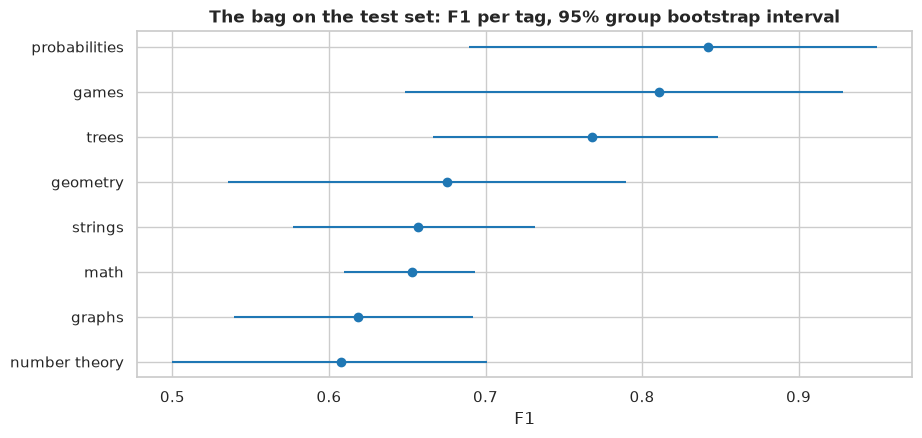

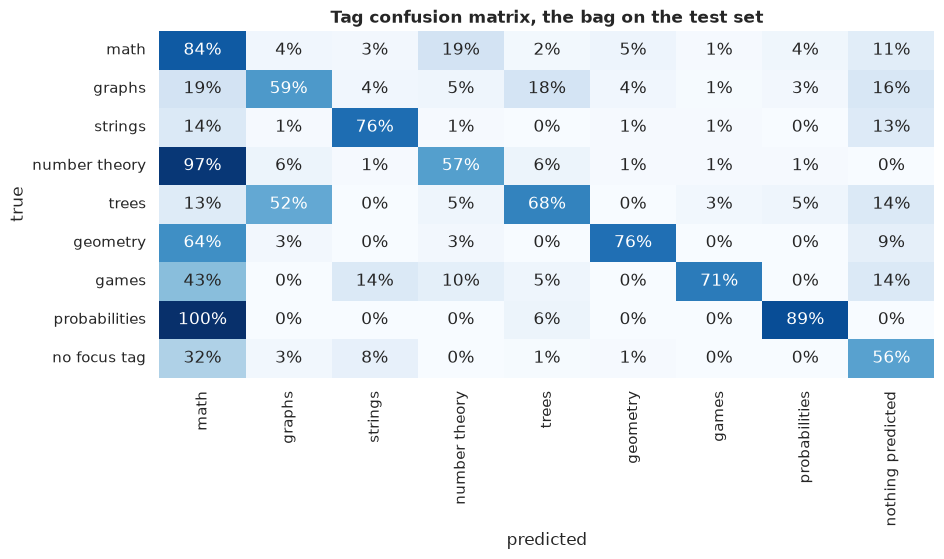

In [27]:
bag_per_tag = test_results["bag"].per_tag.loc[ALL_PROBLEMS]
ax = plot_intervals(bag_per_tag.sort_values("f1", ascending=False), "f1", "f1_low", "f1_high")
ax.set(title="The bag on the test set: F1 per tag, 95% group bootstrap interval", xlabel="F1")
plt.show()
ax = plot_tag_confusion(test_results["bag"].tag_confusion)
ax.set(title="Tag confusion matrix, the bag on the test set")
plt.show()

In [28]:
test_kept = ~test.index.isin(self_identifying.index)
pd.DataFrame(
    {
        "all test problems": {
            name: test_results[name].macro_f1 for name in ["bag", TFIDF, LORA_METHOD, PRIOR_METHOD]
        },
        "without the self-identifying": {
            name: evaluate(test_labels[test_kept], test_predictions[name][test_kept]).macro_f1
            for name in ["bag", TFIDF, LORA_METHOD, PRIOR_METHOD]
        },
    }
).rename_axis("test macro F1").round(4)

,all test problems,without the self-identifying
test macro F1,,
bag,0.7039,0.7036
tfidf,0.6888,0.6885
modernbert_lora,0.6954,0.6948
label_prior,0.1487,0.1485


**What the test set shows**
- **The bag scores a macro F1 of 0.704** [0.666, 0.737], and a micro F1 of 0.663.
- **Bagging helps a little, again.** The single models score 0.685 to 0.708 (0.694 on average).
  The bag beats four of them, by 0.010 to 0.019, and falls 0.004 short of the best, fold 1's
  ([-0.026, 0.017]); every paired interval includes 0. Choosing fold 1's model now would be
  choosing on the test set: as for `modernbert_lora`, the bag mostly protects from the weak
  models.
- **Against the references**: +0.015 [-0.013, 0.042] over the TF-IDF baseline and +0.008
  [-0.019, 0.034] over `modernbert_lora`'s bag. The highest test score of the three, but within
  the noise, and the dev set ranks it last: the test set is not where methods are chosen
  ([ADR 0001](../docs/adr/0001-model-selection-protocol.md)). The label prior scores 0.149.
- **Per tag**, ahead of the TF-IDF baseline on `math` (0.653 against 0.619), `graphs` (0.618
  against 0.557), `number theory` (0.607 against 0.518) and `probabilities` (0.842 against
  0.800), behind on `games` (0.811 against 0.878) and `geometry` (0.676 against 0.706), level on
  `trees` and `strings`.
- **Without the 16 self-identifying test problems**, the bag scores 0.704 again, and no method
  moves by more than 0.001.

## 7. Latency and memory

**The framework's harness** (`python -m codeforces_tags.tracking latency`, `evaluation/timing.py`)
times the method as the CLI runs it. It loads the method folder (`load_method`, which checks the
sha256 of the five weight files, then reads them, into pinned CPU memory when the model is on the
GPU), then calls `predict` on
one raw problem at a time, after a warm-up: `preprocess()`, the token ids, five forward passes
with each fold model's weights copied into one model in turn, the mean probability and the
thresholds. It times 50 dev problems drawn with `LATENCY_SEED`, then one `predict` call over the
50. `tracking latency` ran on the GPU that froze the method, an RTX 2080 Ti (`latency.csv`), and
the method's `latency-cpu` command on the CPU, in float32 (`analysis/cpu/latency.csv`).
`modernbert_lora`'s timings are beside them. A method is eligible for the CLI only when the
slowest problem of its `latency.csv` takes less than PROBLEM.md's 10 seconds
([ADR 0004](../docs/adr/0004-tagging-method-framework.md)):

,problems,median_s,p95_s,max_s,over budget,"one call, all problems (s)",load (s),eligible (max under budget)
timed,,,,,,,,
"modernbert_base_full, GPU",50.0,0.36,0.44,0.47,0.0,4.45,26.21,True
"modernbert_base_full, CPU",50.0,3.88,9.89,13.58,3.0,326.96,12.85,False
"modernbert_lora, GPU",50.0,0.33,0.38,0.50,0.0,8.32,10.34,True
"modernbert_lora, CPU",50.0,10.91,16.07,19.57,31.0,700.53,5.61,False


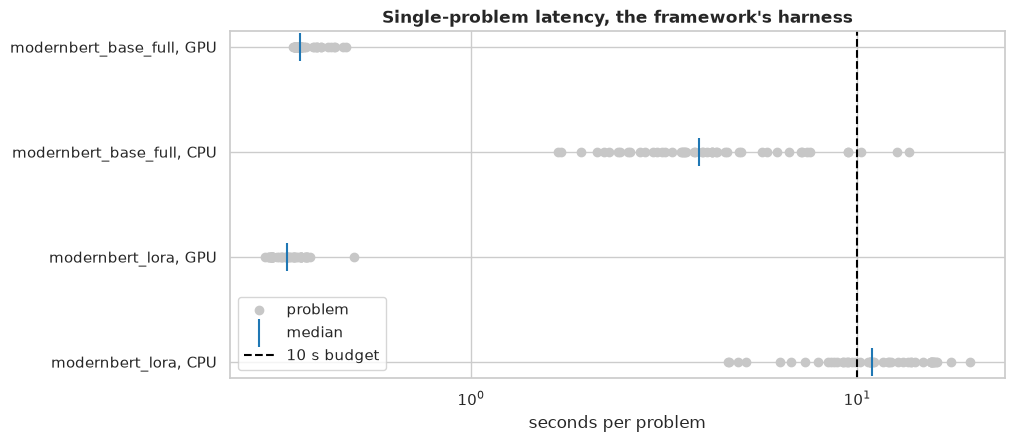

In [29]:
latencies = {
    f"{METHOD}, GPU": load_latency(METHOD_DIR),
    f"{METHOD}, CPU": load_latency(ANALYSIS_DIR / CPU_LATENCY_FOLDER),
    f"{LORA_METHOD}, GPU": load_latency(LORA_DIR),
    f"{LORA_METHOD}, CPU": load_latency(LORA_DIR / ANALYSIS_FOLDER / CPU_LATENCY_FOLDER),
}
latency_table = pd.DataFrame(
    {
        name: {
            "problems": len(timing.seconds),
            **latency_summary(timing.seconds).to_dict(),
            "over budget": int((timing.seconds >= LATENCY_BUDGET_S).sum()),
            "one call, all problems (s)": timing.bulk_s,
            "load (s)": timing.load_s,
        }
        for name, timing in latencies.items()
    }
).T.rename_axis("timed")
latency_table["eligible (max under budget)"] = latency_table["max_s"] < LATENCY_BUDGET_S
notebook_latency = pd.read_csv(NOTEBOOK_LATENCY_FILE, float_precision="round_trip")
notebook_cpu_ids = notebook_latency.loc[notebook_latency["device"] == "cpu", "sample_id"].unique()
display(latency_table.round(2))
ax = plot_latency({name: timing.seconds for name, timing in latencies.items()})
ax.set(title="Single-problem latency, the framework's harness")
plt.show()

**The slowest problems on the CPU** are those with the longest inputs: a forward pass grows with
the input's length, and the bag runs five of them.

In [30]:
cpu_seconds = latencies[f"{METHOD}, CPU"].seconds
print(
    f"CPU seconds against input tokens, Spearman correlation: "
    f"{cpu_seconds.corr(input_tokens.reindex(cpu_seconds.index), method='spearman'):.2f}"
)
pd.DataFrame(
    {
        "CPU s": cpu_seconds,
        "GPU s": latencies[f"{METHOD}, GPU"].seconds,
        "input tokens": input_tokens.reindex(cpu_seconds.index),
        "solution characters": dev["source_code"].str.len().reindex(cpu_seconds.index),
        "statement characters": dev["statement"].str.len().reindex(cpu_seconds.index),
        "timed on the CPU by the first notebook": cpu_seconds.index.isin(notebook_cpu_ids),
    }
).nlargest(SLOWEST_SHOWN, "CPU s").round(2)

CPU seconds against input tokens, Spearman correlation: 0.94


,CPU s,GPU s,input tokens,solution characters,statement characters,timed on the CPU by the first notebook
sample_id,,,,,,
3181,13.58,0.47,2048,6501,724,False
3458,12.72,0.47,2048,4695,1957,False
4843,10.24,0.44,1712,3380,2065,False
4656,9.46,0.43,1584,3368,1514,False
3770,9.45,0.44,1603,4181,846,False


**One model against the bag.** The notebook that first trained the method timed three ways to
serve on the same GPU, with the same weights, before the migration
(`analysis/notebook_latency.csv`): one fold model, the bag with the weights swapped (as the method
serves it), and the bag with the five models resident on the GPU, at five times the memory; and
one model and the swapped bag on the CPU. Its path was the method's: the raw record,
`preprocess()`, the token ids, the forward passes and the thresholds, one problem at a time after
a warm-up.

In [31]:
notebook_table = (
    notebook_latency.groupby(["device", "model"], sort=False)["seconds"]
    .apply(latency_summary)
    .unstack()
)
notebook_table.insert(
    0, "problems", notebook_latency.groupby(["device", "model"], sort=False).size()
)
gpu_medians = notebook_table.loc["gpu", "median_s"]
swap_s = (gpu_medians["bag, weights swapped"] - gpu_medians["bag, five models resident"]) / len(
    names
)
harness_ids = set(cpu_seconds.index)
print(
    "problems also timed by the harness: "
    + ", ".join(
        f"{device} {len(set(ids) & harness_ids)} of {len(set(ids))}"
        for device, ids in notebook_latency.groupby("device", sort=False)["sample_id"]
    )
)
same_problems = cpu_seconds.loc[notebook_cpu_ids]
print(
    f"the harness on the {len(same_problems)} problems the notebook timed on the CPU: median "
    f"{same_problems.median():.1f} s, max {same_problems.max():.1f} s"
)
print(
    f"copying one fold model's weights into the GPU model, from the medians: {swap_s * 1000:.0f} ms"
)
notebook_table.round(3)

problems also timed by the harness: gpu 50 of 50, cpu 10 of 10
the harness on the 10 problems the notebook timed on the CPU: median 4.2 s, max 6.2 s
copying one fold model's weights into the GPU model, from the medians: 52 ms


problems  median_s  p95_s  max_s
device model                                                      
gpu    one model                        50     0.026  0.044  0.055
       bag, weights swapped             50     0.362  0.438  0.479
       bag, five models resident        50     0.100  0.184  0.218
cpu    one model                        10     0.729  1.143  1.294
       bag, weights swapped             10     4.513  6.499  7.437

**Memory**, from the weight lists rather than a loaded model: each fold model's weights file
(`trained.json`, float32) is what the GPU holds for the one model and what pinned CPU memory holds
per set of weights (pinning rounds each tensor's block up, so the pinned memory is larger than
the files). The pretrained snapshot gives only the configuration and the tokenizer. Beside them,
`modernbert_lora`'s five adapters, and the ModernBERT-large encoder they share:

In [32]:
fold_bytes = pd.Series({fold: entry["bytes"] for fold, entry in trained["folds"].items()})
snapshot_bytes = sum((snapshot / name).stat().st_size for name in pretrained["files"])
lora_model_dir = model_dir(LORA_METHOD)
lora_trained = json.loads((lora_model_dir / TRAINED_FILE).read_text(encoding="utf-8"))
lora_pretrained = json.loads((lora_model_dir / PRETRAINED_FILE).read_text(encoding="utf-8"))
lora_adapter_bytes = pd.Series(
    {fold: entry["bytes"] for fold, entry in lora_trained["folds"].items()}
)
lora_encoder_bytes = (
    (snapshot_folder(lora_pretrained["repo_id"], lora_pretrained["revision"]) / ENCODER_FILE)
    .stat()
    .st_size
)
pd.Series(
    {
        f"{METHOD}: one fold model, MiB": fold_bytes.iloc[0] / 2**20,
        f"{METHOD}: {len(fold_bytes)} fold models, GiB": fold_bytes.sum() / 2**30,
        f"{METHOD}: pretrained files read, MiB": snapshot_bytes / 2**20,
        f"{LORA_METHOD}: one adapter, MiB": lora_adapter_bytes.iloc[0] / 2**20,
        f"{LORA_METHOD}: {len(lora_adapter_bytes)} adapters, GiB": lora_adapter_bytes.sum() / 2**30,
        f"{LORA_METHOD}: the encoder they share, GiB": lora_encoder_bytes / 2**30,
    },
    name="float32 weights",
).round(2).to_frame()

,float32 weights
"modernbert_base_full: one fold model, MiB",570.73
"modernbert_base_full: 5 fold models, GiB",2.79
"modernbert_base_full: pretrained files read, MiB",2.06
"modernbert_lora: one adapter, MiB",58.97
"modernbert_lora: 5 adapters, GiB",0.29
"modernbert_lora: the encoder they share, GiB",1.47


**What latency and memory show**
- **On the GPU, under the budget**: 0.36 s per problem at the median for the bag, 0.44 s at the
  95th percentile, 0.47 s at most; one call over the 50 problems takes 4.5 s, and loading the
  method 26.2 s, most of it hashing the five weight files of 571 MiB and pinning them. The
  method is eligible for the CLI. Most of a prediction is the five weight copies: the first
  notebook measured 0.03 s for one fold model and 0.10 s for the five models resident, so each
  copy takes about 52 ms.
- **On the CPU, over the budget for the longest inputs**: 3.9 s at the median, but 13.6 s at most,
  and three of the 50 problems take over 10 s. The slowest, problem 3181, has a 6,501-character
  solution that fills the 2,048-token input, as does the next, problem 3458 (12.7 s); the time
  follows the input's length (Spearman correlation 0.94). The first notebook's CPU timings, 4.5 s
  at the median and 7.4 s at most, were measured on 10 of the same 50 problems, none of the
  three slowest; the harness took 4.2 s at the median and 6.2 s at most on those 10. The
  bag meets PROBLEM.md's 10 s on the GPU with room to spare, and on the CPU only for shorter
  inputs; `modernbert_lora`, whose larger encoder reads at most half as many tokens, takes 10.9 s
  at the median on the CPU.
- **Memory**: one model's weights (571 MiB) on the GPU with the weights swapped, against 2.79 GiB
  for the five resident; the swap keeps the five sets of weights in pinned CPU memory instead.
  `modernbert_lora`'s five adapters take 59 MiB each, beside the ModernBERT-large encoder they
  share (1.47 GiB).

## 8. Takeaways and next steps

**Results**
- **Tuning on one fold** (section 4): 30 trials, 3.6 hours of training; the chosen configuration
  trains every weight for 5 epochs at a learning rate of 9.3e-5 (batch 32, weight decay 7.6e-4,
  classifier dropout 0.07, positives weighted by the class ratio to the power 0.61), and scores
  0.665 on fold 0. Full fine-tuning needs more epochs than LoRA, and collapsed less.
- **Out of fold** (section 5): a macro F1 of 0.653 [0.632, 0.671], level with the TF-IDF
  baseline (0.663) and with `modernbert_lora` (0.661), far above the label prior (0.149), with a
  per-tag picture close to `modernbert_lora`'s: ahead of the TF-IDF baseline on `number theory`,
  behind on `trees` and `games`; unlike `modernbert_lora`, level on `math` and clearly behind on
  `strings`.
- **Test set, scored once** (section 6): the bag scores 0.704 [0.666, 0.737], above four of its
  five single models, and level with the TF-IDF baseline (0.689) and `modernbert_lora`'s bag
  (0.695).
- **Latency** (section 7): under the ten seconds on the GPU (0.36 s at the median, 0.47 s at
  most), with one model on the GPU and the others' weights swapped in; on the CPU, 3.9 s at the
  median but up to 13.6 s for the longest inputs.

**The migration.** The method is frozen in `assets/methods/modernbert_base_full/` from the study
and the fold models of the notebook that first trained it, adopted rather than trained again: the
migration check found its thresholds, scores and every macro F1 above equal to what that notebook
reported, and that no test prediction differs. `verify` re-scores every dev fold and the test set
from the cached weights (gap 0), and `verify --retrain` trains the fold models again and checks
them on bounds declared beforehand
([ADR 0005](../docs/adr/0005-fine-tuned-model-protocol.md)).

**Which method.** Out of fold, where methods are chosen, the three are level, and the TF-IDF
baseline (0.663) is still the one no fine-tuned method beats. Between the two fine-tuned methods,
`modernbert_lora` is ahead by 0.008, within the noise. Both are eligible for the CLI on the GPU;
on a CPU, this method's bag is the faster one, but it still goes over the budget for its longest
inputs. Where the transformers help is per tag, which points to combining the methods rather
than choosing one.

**Next steps**
- **Combine the methods**: the TF-IDF baseline leads on `strings`, `trees` and `games`, the
  transformers on `number theory` and `probabilities` and, depending on the method, `math`. An
  average of their probabilities, or a per-tag stacking chosen out of fold, from the frozen
  out-of-fold scores (`scores.csv`) of `modernbert_base_full`, `modernbert_lora` and `tfidf`,
  as a composite method of the framework.
- **Fit the CPU budget**: the problems over 10 s are the longest inputs. Serving fewer fold
  models on a CPU, or quantising the weights, could bring them under it, at a cost to measure out
  of fold.
- **Measure the training noise**: `verify --retrain` trains the five fold models again from
  their seeds; its agreement with the frozen ones says how much of the gaps between methods a new
  training would move.
- **Search where the optimum is**: the chosen trial sits at the top of the epoch range (5), so a
  next study should allow more epochs; and it should not prune before the warmup ends, or before
  half the epochs. A new study makes a new method, frozen under a new name.
- **Tune across folds**, rather than on one, to choose on a less noisy score.
- **Read more of the problem**: the notes (which the TF-IDF baseline reads) and the sample inputs
  and outputs, which a 2,048-token input has room for.